# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

os.environ["JAX_PLATFORM_NAME"] = "cpu"  # must be set before importing jax

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.ticker as mticker
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-05-20 13:34:19,435:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-20 13:34:19,435 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-20 13:34:21,475 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux
import skewerjax.utils.plotting_tools as pt

import skewerjax.optical_depth.optical_depth as od

from skewerjax.constants.physical_constants import phys

In [3]:
x_axis_key = "velocities"
assert x_axis_key in ("wavelengths", "velocities"), "x_axis_key should be either 'wavelengths', or 'velocities'"

# Cosmology

In [4]:
# Create cosmology object
cosmology = Cosmology(H0=phys.H0, Omega_r_0=0.0, Omega_m_0=1.0, Omega_k_0=0.0, Omega_lambda_0=0.0)
# Define which cosmology to use, this is set as default to 0 since skewer and cosmology objects can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time
ii_cosmology = 0

# Lines

In [ ]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "HI-LyA-1206"]) # "SiIII-1206", "SiII-1190", "SiII-1193" # "HI-LyA-1206", "HI-LyA-1193", "HI-LyA-1190"

# Fields

In [6]:
L_box = 110.7  # Mpc

In [ ]:
N_absorvers = 5
Delta = 0.5

n0_HI = 1e-11
T0_HI = 1e5

n0_SiIII = 1e-11
T0_SiIII = 1e5

n0_SiII = 1e-11
T0_SiII = 1e5

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-5, C0=T0_HI, L_box=L_box, base_seed=0)),    # UNITS: [K]
        "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-20, C0=n0_HI, L_box=L_box, base_seed=0)), # [cm^-3]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    # "SiIII": {
    #     "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-5, C0=T0_SiIII, L_box=L_box, base_seed=0)),    # UNITS: [K]
    #     "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-20, C0=n0_SiIII, L_box=L_box, base_seed=0)), # [cm^-3]
    #     "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
    #     "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
    #     "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    # },
    # "SiII": {
    #     "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-5, C0=T0_SiII, L_box=L_box, base_seed=0)),    # UNITS: [K]
    #     "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-20, C0=n0_SiII, L_box=L_box, base_seed=0)), # [cm^-3]
    #     "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
    #     "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
    #     "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    # },
})

In [8]:
# T0_HI = 1e5
# T0_Si = 2e6
# n0_min = 1e-16
# n0_max = 1e-10
# def pk_template(k: jnp.ndarray, A, n, k0, k_cut):
#     # P(k) = A (k/k0)^n exp[-(k/k_cut)^2]
#     kk = jnp.maximum(k, 1e-12)
#     return A * (kk / k0) ** n * jnp.exp(-(kk / k_cut) ** 2)
# number_density_sampler = toy_samplers.number_density_sampler_gaussian_3d(
#     key=jax.random.PRNGKey(0),
#     pk_of_k=lambda k: pk_template(k, A=5.0, n=-2.5, k0=2.0, k_cut=50.0),
#     n0_min=n0_min, n0_max=n0_max, L_box=L_box,
#     grid_shape=(256, 256, 256), contrast=1.2,
# )
# fields = Fields({
#     "HI": {
#         "temperature": ScalarField(toy_samplers.temperature_sampler(T0_HI, T0_HI, L_box)),    # UNITS: [K]
#         "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
#         "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
#         "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
#         "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
#     },
#     "SiIII": {
#         "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
#         "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
#         "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
#         "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
#         "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
#     },
#     # "SiII": {
#     #     "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
#     #     "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
#     #     "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
#     #     "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
#     #     "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
#     # },
# })

In [9]:
z_box = 2.0

scale_factor_right  = 1 / (1 + z_box)
scale_factor_left = float(cosmology.solve_a_of_x(
    ICs=jnp.array([1/(1+z_box)]),
    x_eval_Mpc=jnp.linspace(start=L_box, stop=0.0, num=2)
)[0, -1])

In [10]:
delta_lambda_limits = 1.0
min_lambda = jnp.min(line_bundle.lambda0_A)/scale_factor_right - delta_lambda_limits
max_lambda = jnp.max(line_bundle.lambda0_A)/scale_factor_left + delta_lambda_limits

resolution_lambda_A = 0.1 # in Angstroms
N_lambda = int((max_lambda - min_lambda) / resolution_lambda_A)

In [11]:
lambda0_anchor_key = "Ly-\alpha"
if lambda0_anchor_key == "Ly-\alpha":
    lambda0_anchor = line_bundle.lines_for_species('HI')[0].lambda0_A
elif lambda0_anchor_key == None:
    lambda0_anchor = 1.0

In [12]:
if x_axis_key == "wavelengths":
    x_label = r"$\lambda\ [\mathrm{\AA}]$"
    min_plot = min_lambda
    max_plot = max_lambda
    x_axis_array = jnp.linspace(min_plot, max_plot, N_lambda)  # in Angstroms
    wavelengths = x_axis_array
elif x_axis_key == "velocities":
    if lambda0_anchor_key == None:
        x_label = r"$c\, \ln\left(\lambda \left[\mathrm{\AA}\right]\right)\; \left[\mathrm{km\,/\,s}\right] $"
    else:
        x_label = r"$c\, \ln\left( \frac{\lambda}{\lambda_\dagger}\right)\; \left[\mathrm{km\,/\,s}\right]$"
    min_plot = phys.c*1e-3*jnp.log(min_lambda/lambda0_anchor)
    max_plot = phys.c*1e-3*jnp.log(max_lambda/lambda0_anchor)
    x_axis_array = jnp.linspace(min_plot, max_plot, N_lambda)
    wavelengths = lambda0_anchor * jnp.exp(x_axis_array/(phys.c*1e-3))

# Skewers

In [ ]:
N_grid_skewers = 4
N_ppsk = 1024
points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y")
points = jnp.reshape(points_grid_skewers, (N_grid_skewers**2, N_ppsk, 3))

xx_LoS = jnp.linspace(start=0.0, stop=L_box, num=N_ppsk)
scale_factors = cosmology.solve_a_of_x(
    ICs=jnp.array([scale_factor_left]),
    x_eval_Mpc=xx_LoS
)[0]

a0_per_skewer = scale_factors[N_ppsk-1]
x0_per_skewer = points_grid_skewers[0, 0, -1, 1]
skewer_bundle = SkewerBundle(spatial_points=points, cosmologies=cosmology, a0=a0_per_skewer, x0=x0_per_skewer)

2026-05-20 13:34:52,893 - INFO - Initializing SkewerBundle with 25 skewers, 1024 points per skewer
2026-05-20 13:34:53,282 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 25 skewers
2026-05-20 13:34:53,481 - INFO - All skewers set to absorption mode
2026-05-20 13:34:53,826 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-05-20 13:34:55,454 - INFO - Computing comoving distances along skewer direction
2026-05-20 13:34:55,925 - INFO - Computing scale factors from cosmology
2026-05-20 13:35:14,824 - INFO - Storing quadri-vectors
2026-05-20 13:35:15,259 - INFO - SkewerBundle initialization complete


In [14]:
sampled_fields = fields.sample(skewer_bundle.quadri_vectors[ii_cosmology], skewer_bundle.los_directions)

# Optical depth

In [15]:
scale_factor_obs = 1.0

In [16]:
scale_factors_obs = jnp.repeat(scale_factor_obs, skewer_bundle.N_sk)
optical_depth = od.compute_optical_depth(skewer_bundle, wavelengths, line_bundle, fields, scale_factors_obs) # Compute optical depth
F_over_F0 = jnp.exp(-optical_depth)

2026-05-20 13:35:23,404 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, Voigt impl=ExoJAX
2026-05-20 13:35:23,411 - INFO - [OPTICAL_DEPTH] Extracting 25 skewers with 1024 points each
2026-05-20 13:35:23,683 - INFO - [OPTICAL_DEPTH] Computing line profiles for 2 lines across 2 species
2026-05-20 13:35:31,166 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (2, 25, 1024, 1984)
2026-05-20 13:35:31,173 - INFO - [OPTICAL_DEPTH] Tiling fields for 2 species to line-level
2026-05-20 13:35:33,412 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (2, 25, 1024)
2026-05-20 13:35:33,418 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-05-20 13:35:34,772 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (2, 25, 1024, 1984)
2026-05-20 13:35:34,781 - INFO - [OPTICAL_DEPTH] Reorienting 25 skewers based on photon path direction mask
2026-05-20 13:35:35,608 - INFO - [OPTICAL_DEPTH] Arrays reoriented: quadri_vectors (25, 1024, 4), d

In [17]:
optical_depth_grid = jnp.reshape(optical_depth, (line_bundle.n_lines, N_grid_skewers, N_grid_skewers, N_lambda))

In [18]:
%autoreload

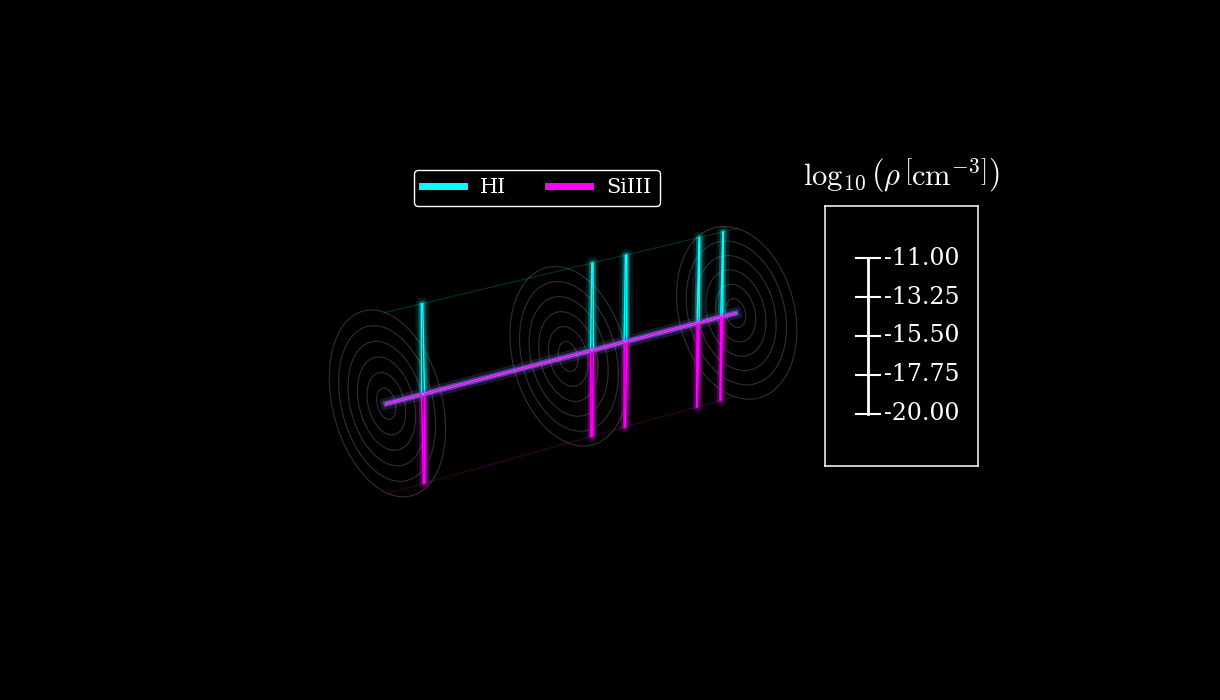

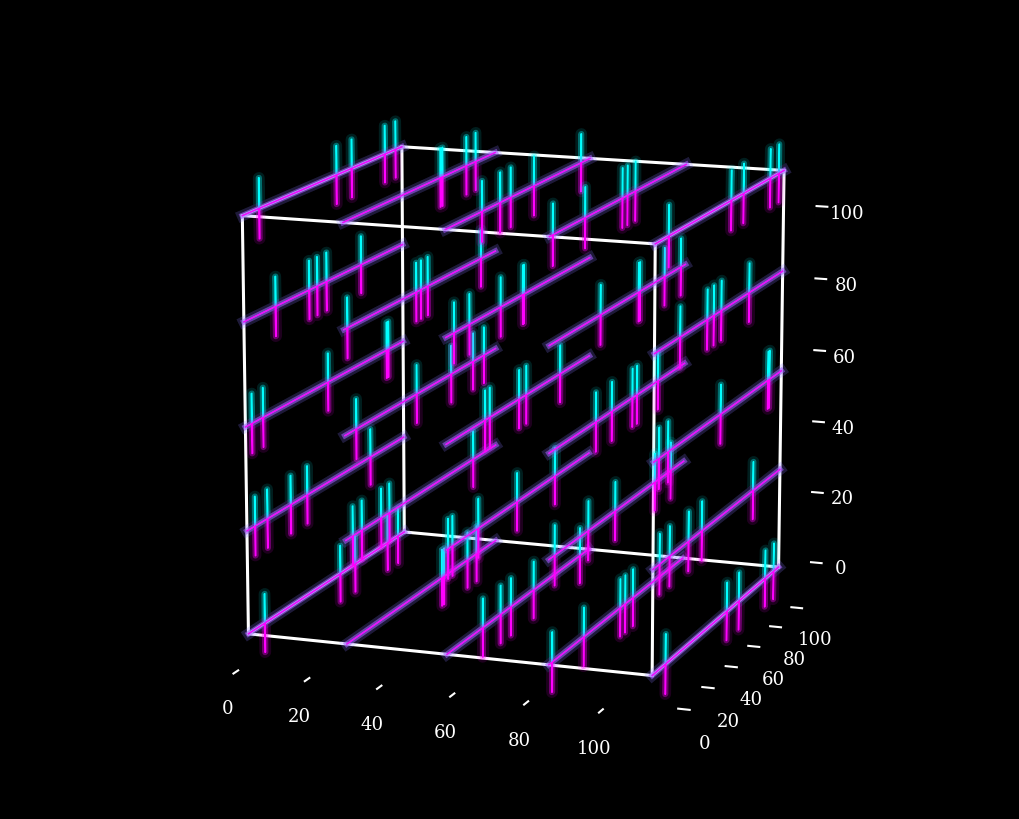

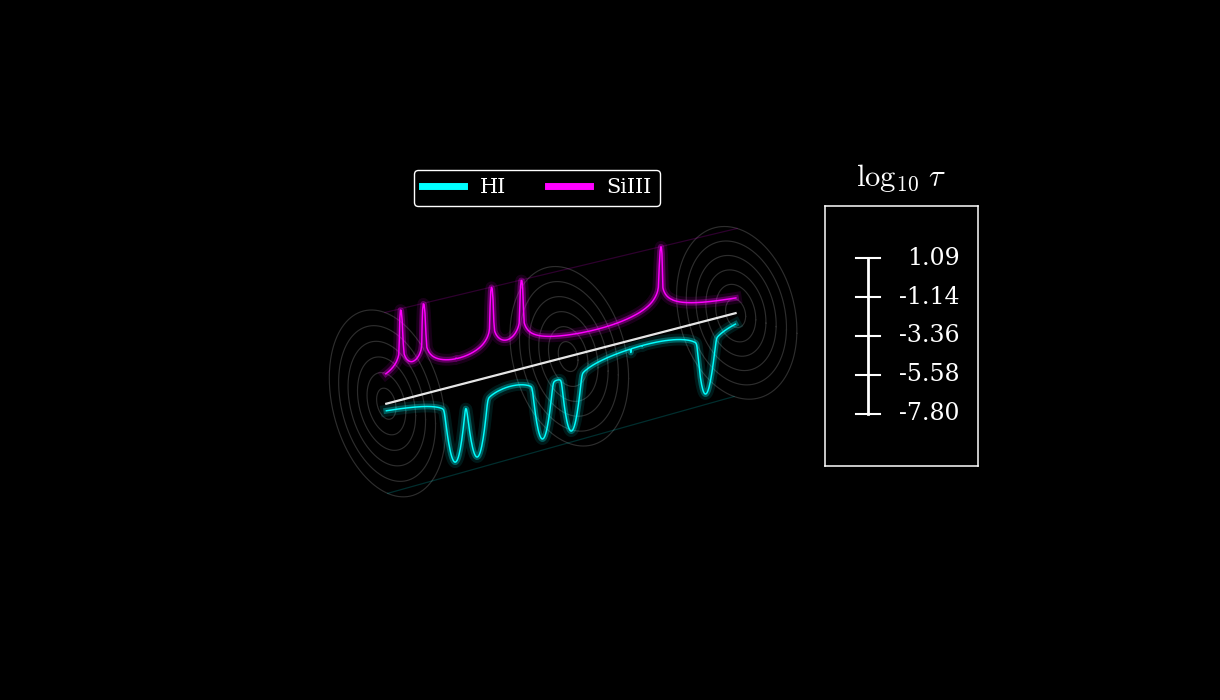

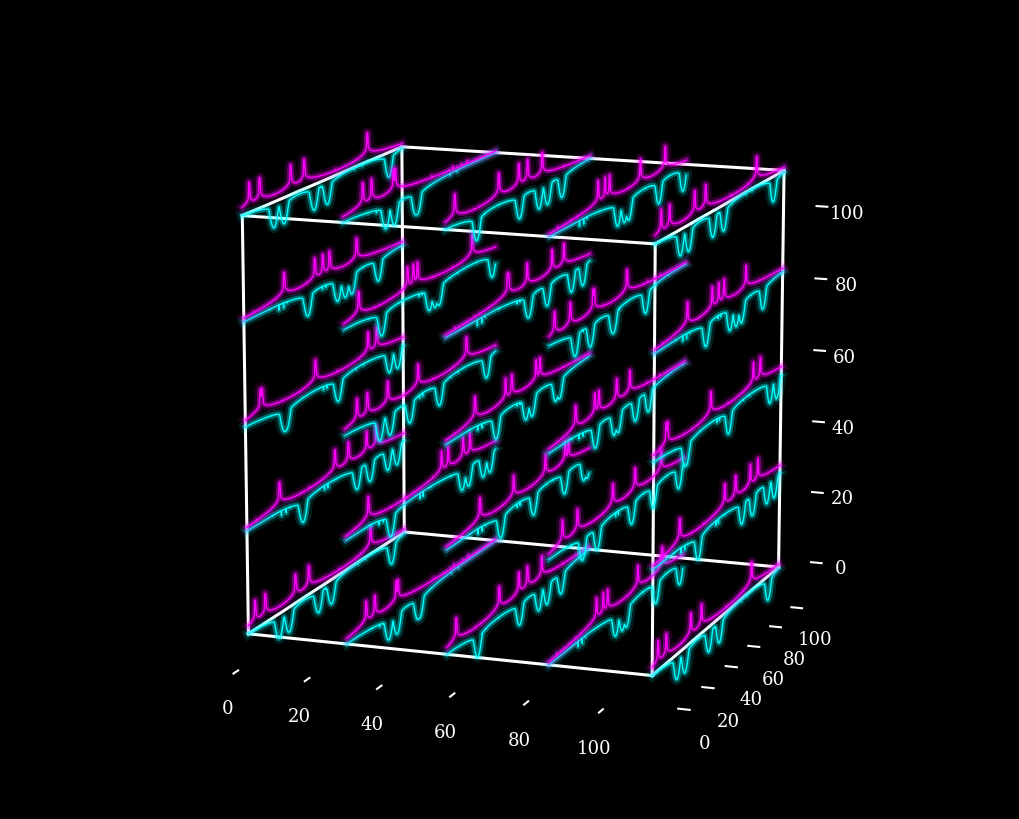

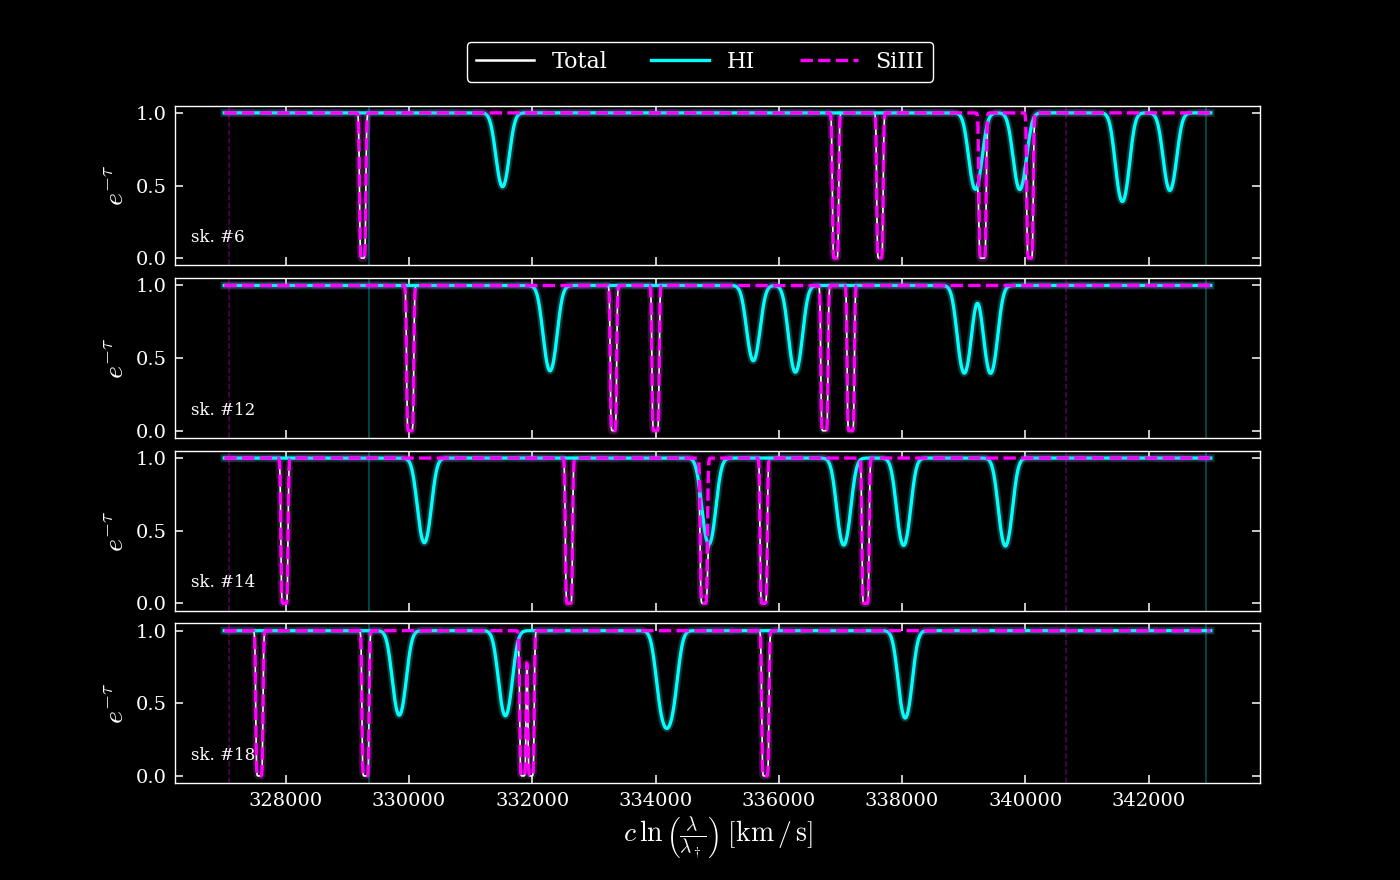

In [19]:
fig_nd, ax_nd = pt.plot_3d_radar_cylinder(
    points=points, sampled_fields=sampled_fields, field="number_density", mode="sampled_fields", skewer_index=0, n_samples_plot=1,
    cylinder_radius=1.5, cylinder_separation=5.2, field_logscale=True, normalization="global", scale_box_x_factor=0.83, legend_y_factor=0.8,
    scale_units_xy=(0.50, 1.05), profile_angle_offset_deg=90.0, n_y_slices=3, field_units=r"$\log_{10}\left(\rho \, \left[\mathrm{cm}^{-3}\right] \right)$",
    view_elev=18, view_azim=-40,
)
fig_cube, ax_cube = pt.plot_3d_neon_ridge_cube(
    points=points, sampled_fields=sampled_fields, field="number_density", mode="sampled_fields", normalization="global",
    field_logscale=True, profile_angle_offset_deg=-90.0, ridge_scale=1.2, elev=13, azim=-70
)
fig_tau, ax_tau = pt.plot_3d_radar_cylinder(
    points=points, mode="optical_depth", optical_depth_grid=optical_depth_grid, line_bundle=line_bundle, skewer_index=0, n_samples_plot=1,
    cylinder_radius=1.5, cylinder_separation=5.2, field_logscale=True, normalization="global", scale_box_x_factor=0.83, legend_y_factor=0.8,
    scale_units_xy=(0.50, 1.05), profile_angle_offset_deg=-90.0, n_y_slices=3, field_units=r"$\log_{10} \, \tau$",
    view_elev=18, view_azim=-40,
)
fig_tau_cube, ax_tau_cube = pt.plot_3d_neon_ridge_cube(
    points=points, mode="optical_depth", optical_depth_grid=optical_depth_grid, line_bundle=line_bundle, skewer_index=0,
    normalization="skewer", field_logscale=True, profile_angle_offset_deg=90.0, ridge_scale=1.2, elev=13, azim=-70
)
fig, axes, idx = pt.plot_transmission_samples_neon(
    F_over_F0=F_over_F0, line_bundle=line_bundle, x_axis_array=x_axis_array, x_label=x_label, x_axis_key=x_axis_key,
    scale_factor_left=scale_factor_left, scale_factor_right=scale_factor_right, lambda0_anchor=lambda0_anchor, N_plot_sample=4, seed=0
)

# Periodic boundary conditions

In [20]:
v_anchor = phys.c*1e-3 * np.log(scale_factor_obs / scale_factor_right)
delta_v_box = phys.c*1e-3 * jnp.log(scale_factor_right/scale_factor_left)
x_axis_array_anchor = x_axis_array - v_anchor

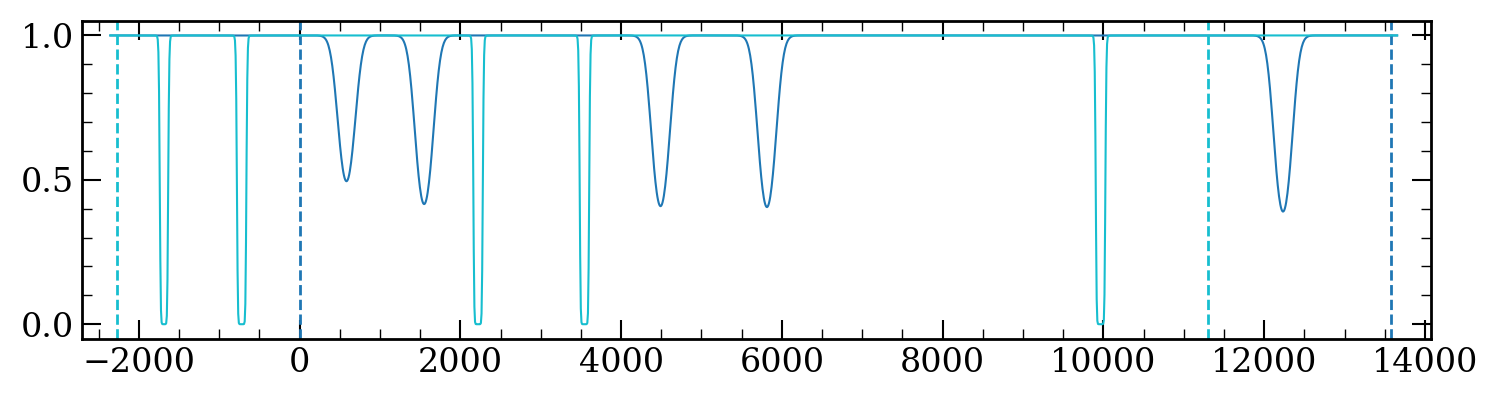

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(15, 4))
colors = plt.cm.tab10(np.linspace(0, 1, len(line_bundle.lines)))
_idx = 0
for i_line, line in enumerate(line_bundle.lines):
    ax.plot(x_axis_array_anchor, F_over_F0[i_line, _idx, :], color=colors[i_line], lw=1.5, linestyle='-', alpha=1.0)
    x_left = phys.c*1e-3 * jnp.log(line.lambda0_A / lambda0_anchor)
    x_right = x_left + delta_v_box
    ax.axvline(x_left, color=colors[i_line], linestyle='--', lw=2.0, alpha=1.0)
    ax.axvline(x_right, color=colors[i_line], linestyle='--', lw=2.0, alpha=1.0)
ax.set_xlim(-2700, delta_v_box+500)
fig.tight_layout()
plt.show()

In [22]:
def wrap_flux_lines_all_skewers(
    x_axis_array_anchor,
    F_over_F0,
    line_bundle,
    lambda0_anchor,
    delta_v_box,
):
    """
    Periodic wrapping of flux lines for all skewers.

    Parameters
    ----------
    x_axis_array_anchor : array, shape (n_pix,)
    F_over_F0 : array, shape (n_lines, n_skewers, n_pix)

    Returns
    -------
    x_axis_array_wrapped : dict[line_key] -> array, shape (n_keep,)
    F_over_F0_wrapped    : dict[line_key] -> array, shape (n_skewers, n_keep)
    line_intervals       : dict[line_key] -> metadata
    """
    x_axis_array_anchor = jnp.asarray(x_axis_array_anchor)
    F_over_F0 = jnp.asarray(F_over_F0)

    x_axis_array_wrapped = {}
    F_over_F0_wrapped = {}
    line_intervals = {}

    for i_line, line in enumerate(line_bundle.lines):
        line_key = str(line.name)

        x_left = phys.c * 1e-3 * jnp.log(line.lambda0_A / lambda0_anchor)
        x_right = x_left + delta_v_box

        # Same physical selection as in your original function
        mask = (x_axis_array_anchor >= x_left) & (x_axis_array_anchor < x_right)
        idx = jnp.where(mask)[0]

        x_crop = x_axis_array_anchor[idx]                         # (n_keep,)
        flux_crop = jnp.take(F_over_F0[i_line], idx, axis=-1)     # (n_skewers, n_keep)

        x_wrap = jnp.mod(x_crop, delta_v_box)
        order = jnp.argsort(x_wrap)

        x_axis_array_wrapped[line_key] = x_wrap[order]                  # (n_keep,)
        F_over_F0_wrapped[line_key] = jnp.take(flux_crop, order, axis=-1)  # (n_skewers, n_keep)

        line_intervals[line_key] = {
            "x_left": x_left,
            "x_right": x_right,
            "x_left_wrapped": jnp.mod(x_left, delta_v_box),
            "n_keep": len(idx),
        }

    return x_axis_array_wrapped, F_over_F0_wrapped, line_intervals

In [23]:
x_axis_array_wrapped, F_over_F0_wrapped, line_intervals = wrap_flux_lines_all_skewers(
    x_axis_array_anchor=x_axis_array_anchor, F_over_F0=F_over_F0,
    line_bundle=line_bundle, lambda0_anchor=lambda0_anchor, delta_v_box=delta_v_box,
)

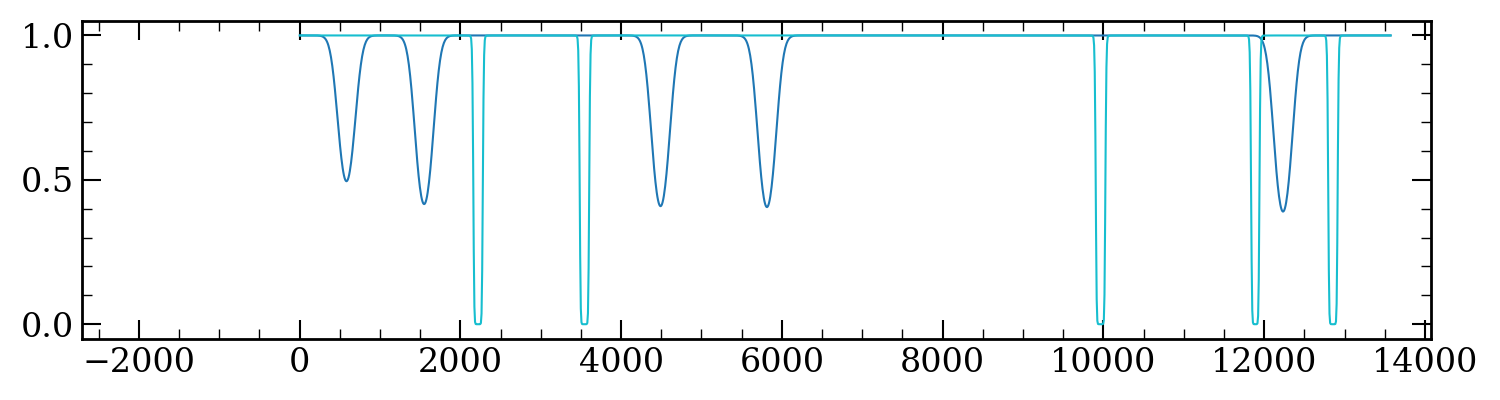

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(15, 4))
colors = plt.cm.tab10(np.linspace(0, 1, len(line_bundle.lines)))
_idx = 0
for i_line, line in enumerate(line_bundle.lines):
    ax.plot(x_axis_array_wrapped[line.name], F_over_F0_wrapped[line.name][_idx, :], color=colors[i_line], lw=1.5, linestyle='-', alpha=1.0)
ax.set_xlim(-2700, delta_v_box+500)
fig.tight_layout()
plt.show()

In [25]:
def compute_total_wrapped_flux_all_skewers(
    x_axis_array_wrapped,
    F_over_F0_wrapped,
    x_common=None,
    n_pix_common=None,
):
    """
    Interpolate all wrapped line fluxes onto a common x-axis and compute
    the total transmitted flux by multiplying the individual contributions.

    Parameters
    ----------
    x_axis_array_wrapped : dict[line_key] -> array, shape (n_pix_line,)
        Wrapped x-coordinates for each line, already sorted in [0, delta_v_box).

    F_over_F0_wrapped : dict[line_key] -> array, shape (n_skewers, n_pix_line)
        Wrapped transmitted flux for each line.

    x_common : array, optional
        Common x-axis where all lines will be interpolated. If None, it is built
        automatically as a uniform grid over the full wrapped domain.

    n_pix_common : int, optional
        Number of pixels for the automatic common grid if x_common is None.
        If None, uses the maximum number of pixels among all wrapped lines.

    Returns
    -------
    x_common : array, shape (n_pix_common,)
        Common wrapped x-axis.

    F_interp_dict : dict[line_key] -> array, shape (n_skewers, n_pix_common)
        Each line interpolated onto x_common.

    F_total : array, shape (n_skewers, n_pix_common)
        Total transmitted flux, i.e. product over all lines.
    """
    keys = list(x_axis_array_wrapped.keys())
    if len(keys) == 0:
        raise ValueError("No wrapped lines were provided.")

    # Infer common domain size from wrapped coordinates
    xmax = max(float(jnp.max(x_axis_array_wrapped[key])) for key in keys)

    if x_common is None:
        if n_pix_common is None:
            n_pix_common = max(len(x_axis_array_wrapped[key]) for key in keys)
        x_common = jnp.linspace(0.0, xmax, n_pix_common)

    x_common = jnp.asarray(x_common)

    F_interp_dict = {}
    F_total = None

    for key in keys:
        x_line = jnp.asarray(x_axis_array_wrapped[key])               # (n_line_pix,)
        F_line = jnp.asarray(F_over_F0_wrapped[key])                 # (n_skewers, n_line_pix)

        # Interpolate each skewer independently onto x_common
        F_interp = jnp.stack(
            [jnp.interp(x_common, x_line, F_line[i_sk]) for i_sk in range(F_line.shape[0])],
            axis=0,
        )  # (n_skewers, n_pix_common)

        F_interp_dict[key] = F_interp

        if F_total is None:
            F_total = F_interp
        else:
            F_total = F_total * F_interp

    return x_common, F_interp_dict, F_total

In [26]:
x_common, F_interp_dict, F_total = compute_total_wrapped_flux_all_skewers(
    x_axis_array_wrapped=x_axis_array_wrapped,
    F_over_F0_wrapped=F_over_F0_wrapped,
    n_pix_common=2048,   # optional
)

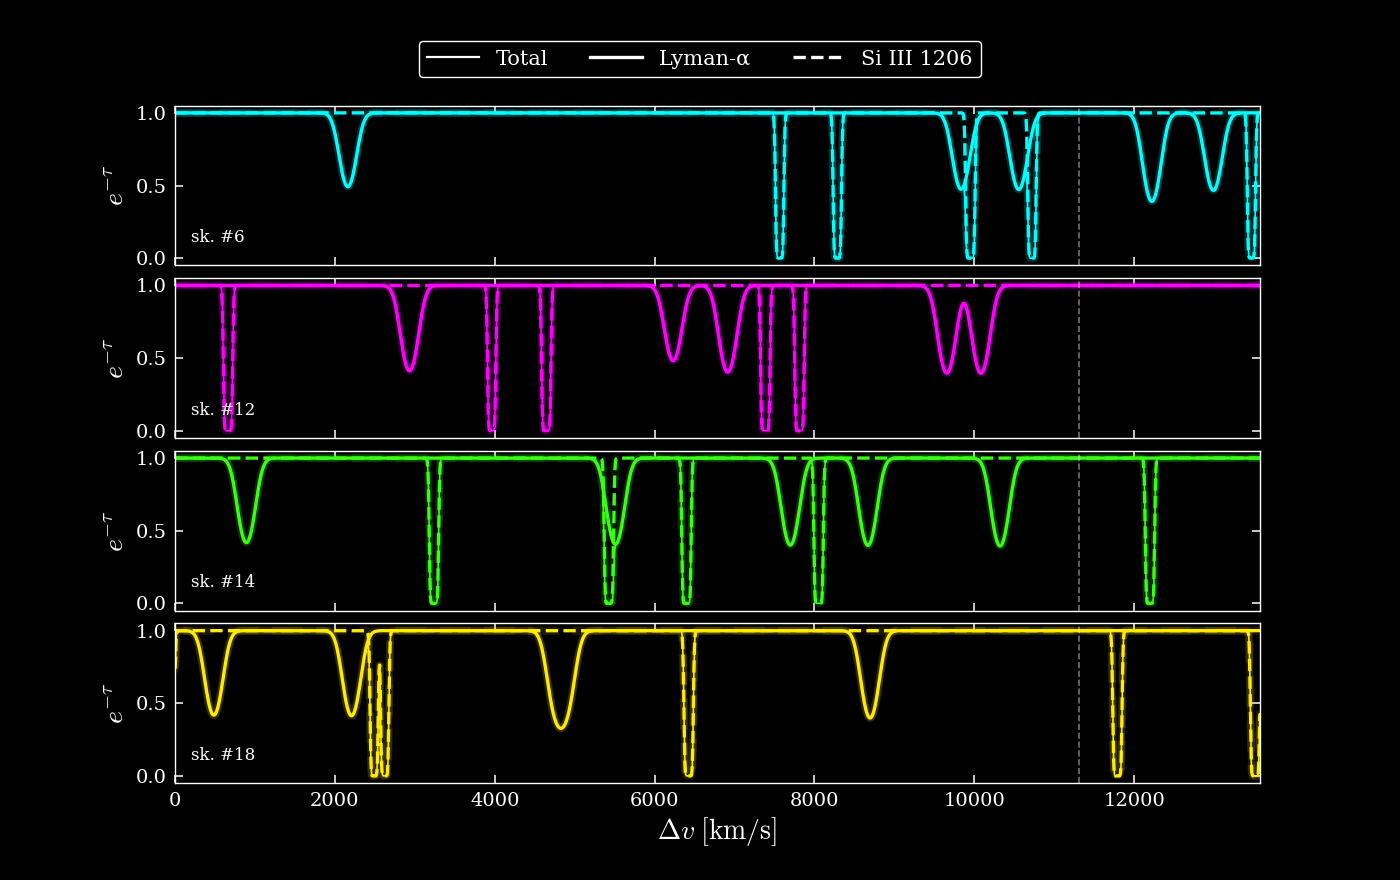

In [27]:
def plot_wrapped_transmission_samples_neon(
    F_total,
    F_interp_dict,
    x_common,
    line_intervals,
    delta_v_box,
    N_plot_sample=4,
    seed=0,
    sample_indices=None,
    linestyles=("-", "--", "-.", ":", (0, (3, 1, 1, 1)), (0, (5, 2))),
):
    """
    Dark/neon version of the wrapped transmission plot.

    Expected shapes
    ---------------
    F_total.shape = (N_skewers, N_pix)
    F_interp_dict[key].shape = (N_skewers, N_pix)

    Required line_intervals structure
    ---------------------------------
    line_intervals[key]["x_left_wrapped"]
    """

    F_total = np.asarray(F_total)
    x_common = np.asarray(x_common)
    wrapped_keys = list(F_interp_dict.keys())
    N_skewers = F_total.shape[0]

    if sample_indices is None:
        rng = np.random.default_rng(seed)
        idx = np.arange(N_skewers) if N_plot_sample >= N_skewers else np.sort(rng.choice(N_skewers, size=N_plot_sample, replace=False))
    else:
        idx = np.clip(np.asarray(sample_indices, dtype=int), 0, N_skewers - 1)

    neon = ["#00FFFF", "#FF00FF", "#39FF14", "#FFEA00", "#FF5F1F", "#9D00FF", "#00BFFF", "#FF1493"]
    skewer_color = {sk_idx: neon[i % len(neon)] for i, sk_idx in enumerate(idx)}

    fig, axes = plt.subplots(len(idx), 1, figsize=(14, 2.2 * len(idx)), sharex=True, sharey=True, facecolor="black")
    axes = np.atleast_1d(axes)

    handles = [Line2D([0], [0], color="white", lw=1.6, linestyle="-", label="Total")]

    for ii, sk_idx in enumerate(idx):
        ax = axes[ii]
        ax.set_facecolor("black")
        c = skewer_color[sk_idx]

        ax.plot(x_common, F_total[sk_idx], color=c, lw=5.0, linestyle="-", alpha=0.12)
        ax.plot(x_common, F_total[sk_idx], color=c, lw=1.2, linestyle="-", alpha=1.0)

        for i_line, key in enumerate(wrapped_keys):
            ls = linestyles[i_line % len(linestyles)]
            ax.plot(x_common, F_interp_dict[key][sk_idx], color=c, lw=6.0, linestyle=ls, alpha=0.10)
            ax.plot(x_common, F_interp_dict[key][sk_idx], color=c, lw=2.4, linestyle=ls, alpha=1.0)

            ax.axvline(line_intervals[key]["x_left_wrapped"], color="white", linestyle=ls, lw=1.2, alpha=0.45)

            if ii == 0:
                handles.append(Line2D([0], [0], color="white", lw=2.4, linestyle=ls, label=str(key)))

        ax.text(0.015, 0.12, f"sk. #{sk_idx}", transform=ax.transAxes, color="white", fontsize=12, ha="left", va="bottom")
        ax.set_xlim(0, delta_v_box)
        ax.set_ylim(-0.05, 1.05)
        ax.set_ylabel(r"$e^{-\tau}$", fontsize=20, color="white")
        ax.tick_params(axis="both", which="major", labelsize=14, colors="white", length=6, width=1.1)

        for side in ["top", "right", "bottom", "left"]:
            ax.spines[side].set_color("white")
            ax.spines[side].set_linewidth(1.0)

    axes[-1].set_xlabel(r"$\Delta v \; [\mathrm{km/s}]$", fontsize=20, color="white")

    leg = fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncols=min(len(handles), 7), frameon=True, fontsize=15, handlelength=2.5, facecolor="black", edgecolor="white", framealpha=1.0)
    for text in leg.get_texts():
        text.set_color("white")

    fig.subplots_adjust(top=0.88, hspace=0.08)
    plt.show()

    return fig, axes, idx

fig, axes, idx = plot_wrapped_transmission_samples_neon(
    F_total=F_total,
    F_interp_dict=F_interp_dict,
    x_common=x_common,
    line_intervals=line_intervals,
    delta_v_box=delta_v_box,
    N_plot_sample=4,
    seed=0,
)